# 04 · Ingest documents with layout

When is plain text enough and when do page structure and vision help?

Use original equipment manuals and fault tables rendered as text PDFs and image-only scans. Compare PDF text, layout-aware parsing and a bounded vision-model path on matched pages.

**Measures** — Table-cell fidelity, reading-order errors, numeric exactness and latency by page format.

**Evidence** — Manifest with page IDs and evidence coordinates, plus a failure gallery.

**Runtime** — CPU, separate T4 vision profile. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}
LAB_NUMBER = 4

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Ingest documents with layout

Open the F-250 maintenance manual. The operator asks for the filter-blockage
reading and required action. The desk must keep the number and action on the
same row, and be able to point back to the page. Would your method still work
if the same page arrived as a scan?

[Read the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/2-build-the-evidence-layer/04-ingest-documents-with-layout)

In [6]:
import hashlib
import io
import json
from collections import Counter, defaultdict
from pathlib import Path
from statistics import median
from time import perf_counter

if not COURSE_SMOKE:
    import pymupdf
    import torch
    from PIL import Image
    from pypdf import PdfReader
    from reportlab.pdfgen import canvas
    from transformers import AutoProcessor, Qwen2VLForConditionalGeneration


lab_started = perf_counter()
PAGE_WIDTH, PAGE_HEIGHT = 540, 400
TABLE_X = (40, 185, 285, 500)
TABLE_Y = (154, 188, 226, 264, 302)
MARKERS = ("OVERVIEW", "FAULT MATRIX", "SERVICE NOTES")
HEADER = ("Fault", "Reading", "Required action")
VISION_MAX_TOKENS = 160
FOCUS_FAMILY = "F250"
REFERENCE = ("text PDF", "PDF layout")

ACTIONS = {
    "seal wear": "Check seal housing",
    "sensor drift": "Verify sensor",
    "filter blockage": "Inspect filter",
    "bearing vibration": "Check bearing assembly",
}

## Freeze a set of pages before choosing a reader

The registered development families give each slice the same representation.
Each family contributes one original page. The PDF and scan are two forms of
that page, not two independent examples. Values are fictional and illustrate
document extraction, not field service instructions.

In [7]:
def page_fixture(asset):
    fault = asset["fault"].upper()
    other_faults = [key for key in ACTIONS if key != asset["fault"]][:2]
    rows = [
        list(HEADER),
        [fault, str(asset["limit"]), ACTIONS[asset["fault"]]],
        *[[key.upper(), str(16 - index * 9), ACTIONS[key]] for index, key in enumerate(other_faults)],
    ]
    # Vary the target row position across families to prevent a first-row shortcut.
    if int(asset["family"][1:]) % 2:
        rows[1], rows[3] = rows[3], rows[1]
    return {
        "page_id": f'{asset["manual_id"]}:1',
        "family": asset["family"],
        "slice": asset["slice"],
        "asset": asset["asset"],
        "rows": rows,
        "fault": fault,
        "question": f'What reading and required action does {asset["asset"]} list for {fault}?',
        "expected": {
            "decision": "answer",
            "value": f'{asset["limit"]} | {ACTIONS[asset["fault"]]}',
            "evidence": [f'{asset["manual_id"]}:1'],
        },
    }


dev_assets = assets("dev")
fixtures = [page_fixture(asset) for asset in dev_assets]
assert {fixture["slice"] for fixture in fixtures} == set(SLICES)
assert len({fixture["family"] for fixture in fixtures}) == len(fixtures)
assert digest(cases("dev")) == SPLIT_MANIFEST["dev"]["sha256"]
focus = next(page for page in fixtures if page["family"] == FOCUS_FAMILY)
print("Development page families and slice counts:", dict(Counter(page["slice"] for page in fixtures)))
print("Worked page:", focus)

Development page families and slice counts: {'manual': 2, 'numeric': 2, 'multi_source': 2, 'ambiguity': 2, 'boundary': 2, 'follow_up': 2}
Worked page: {'page_id': 'manual-F-250-r3:1', 'family': 'F250', 'slice': 'follow_up', 'asset': 'F-250', 'rows': [['Fault', 'Reading', 'Required action'], ['FILTER BLOCKAGE', '101', 'Inspect filter'], ['SEAL WEAR', '16', 'Check seal housing'], ['SENSOR DRIFT', '7', 'Verify sensor']], 'fault': 'FILTER BLOCKAGE', 'question': 'What reading and required action does F-250 list for FILTER BLOCKAGE?', 'expected': {'decision': 'answer', 'value': '101 | Inspect filter', 'evidence': ['manual-F-250-r3:1']}}


## Render a searchable page, then remove its text layer

A PDF content stream specifies where to draw text. It can emit columns and
headings in a different order from the order people see. The original PDF
emits the body cells column by column, while the visible rules mark each row.
The scan preserves those visible positions but contains no selectable text.

In [8]:
def render_pdf(fixture):
    file = io.BytesIO()
    page = canvas.Canvas(file, pagesize=(PAGE_WIDTH, PAGE_HEIGHT), invariant=1)
    page.setTitle(f'Facilities manual for {fixture["asset"]}')
    page.setFont("Helvetica-Bold", 19)
    page.drawString(40, 351, f'Equipment manual {fixture["asset"]}')
    page.setFont("Helvetica-Bold", 12)
    for marker, y in (("SERVICE NOTES", 65), ("OVERVIEW", 309), ("FAULT MATRIX", 265)):
        page.drawString(40, y, marker)
    page.setFont("Helvetica", 10)
    page.drawString(40, 288, "Use this matrix only for the equipment identifier above.")
    page.drawString(40, 48, "Check the current revision before using a recorded action.")
    for x in TABLE_X:
        page.line(x, PAGE_HEIGHT - TABLE_Y[0], x, PAGE_HEIGHT - TABLE_Y[-1])
    for y in TABLE_Y:
        page.line(TABLE_X[0], PAGE_HEIGHT - y, TABLE_X[-1], PAGE_HEIGHT - y)
    page.setFont("Helvetica", 12)
    for column, label in enumerate(HEADER):
        page.drawString(TABLE_X[column] + 9, PAGE_HEIGHT - TABLE_Y[0] - 22, label)
    # This affects text-stream order only. Visually the fields remain in their cells.
    for column in range(len(HEADER)):
        for row, values in enumerate(fixture["rows"][1:], start=1):
            page.drawString(TABLE_X[column] + 9, PAGE_HEIGHT - TABLE_Y[row] - 22, values[column])
    page.save()
    return file.getvalue()


def rasterize_as_scan(pdf_bytes):
    with pymupdf.open(stream=pdf_bytes, filetype="pdf") as digital_document:
        raster = digital_document[0].get_pixmap(matrix=pymupdf.Matrix(2, 2), alpha=False)
        image = Image.frombytes("RGB", (raster.width, raster.height), raster.samples)
        with pymupdf.open() as scan_document:
            scan_page = scan_document.new_page(width=PAGE_WIDTH, height=PAGE_HEIGHT)
            scan_page.insert_image(scan_page.rect, stream=raster.tobytes("png"))
            return scan_document.tobytes(), image


def manifest_page(fixture):
    return {
        **{key: fixture[key] for key in ("page_id", "family", "slice", "asset", "question", "fault", "expected")},
        "page_points": [PAGE_WIDTH, PAGE_HEIGHT],
        "coordinates": "PDF points, top left",
        "cells": [
            {
                "row": row, "column": column, "label": value,
                "bbox": [TABLE_X[column], TABLE_Y[row], TABLE_X[column + 1], TABLE_Y[row + 1]],
            }
            for row, values in enumerate(fixture["rows"])
            for column, value in enumerate(values)
        ],
    }


manifest = [manifest_page(fixture) for fixture in fixtures]
for page in manifest:
    width, height = page["page_points"]
    keys = {(item["row"], item["column"]) for item in page["cells"]}
    assert len(keys) == len(page["cells"])
    assert all(0 <= x0 < x1 <= width and 0 <= y0 < y1 <= height
               for x0, y0, x1, y1 in (item["bbox"] for item in page["cells"]))

## Read the stream, geometry or pixels

The plain-text parser tries to reconstruct rows from the sequence after the
table header. The layout parser reads the ruled table and orders headings by
position. Neither has OCR. The vision model sees the raster once per family.
The same pixels form the scan, so there is no second vision observation for
its underlying source format.

In [9]:
def cells_from_text(text):
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    for index in range(len(lines) - len(HEADER) + 1):
        if tuple(lines[index:index + len(HEADER)]) == HEADER:
            tail = lines[index + len(HEADER):]
            next_heading = next((i for i, line in enumerate(tail) if line in MARKERS), len(tail))
            values = tail[:next_heading]
            if len(values) % len(HEADER) == 0:
                return [list(HEADER), *[values[j:j + len(HEADER)] for j in range(0, len(values), len(HEADER))]]
            break
    return []


def parse_text(pdf_bytes):
    text = PdfReader(io.BytesIO(pdf_bytes)).pages[0].extract_text() or ""
    return {"rows": cells_from_text(text), "raw": text, "heading_source": text}


def parse_layout(pdf_bytes):
    with pymupdf.open(stream=pdf_bytes, filetype="pdf") as document:
        page = document[0]
        tables = page.find_tables()
        rows = tables.tables[0].extract() if tables.tables else []
        text = page.get_text(sort=True)
        return {"rows": rows, "raw": text, "heading_source": text}


def parse_vision_output(raw):
    candidate = raw.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
    try:
        parsed = json.loads(candidate)
    except json.JSONDecodeError:
        parsed = None
    valid = (
        isinstance(parsed, dict)
        and set(parsed) == {"rows", "headings"}
        and isinstance(parsed["rows"], list)
        and all(isinstance(row, list) and len(row) == len(HEADER)
                and all(isinstance(cell, str) for cell in row) for row in parsed["rows"])
        and isinstance(parsed["headings"], list)
        and all(isinstance(label, str) for label in parsed["headings"])
    )
    return {
        "rows": parsed["rows"] if valid else [],
        "heading_source": "\n".join(parsed["headings"]) if valid else "",
        "raw": raw,
        "valid_schema": valid,
    }


def parse_vision(image, processor, model):
    prompt = (
        'Read the page exactly. Return JSON with keys "rows" and "headings". "rows" '
        "contains the fault table as arrays of strings including its header. "
        '"headings" contains visible uppercase section headings in top-to-bottom order.'
    )
    message = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt}]}]
    template = processor.apply_chat_template(message, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[template], images=[image], return_tensors="pt").to(model.device)
    with torch.inference_mode():
        output = model.generate(**inputs, do_sample=False, max_new_tokens=VISION_MAX_TOKENS)
    generated = output[0, inputs.input_ids.shape[-1]:]
    answer = parse_vision_output(processor.decode(generated, skip_special_tokens=True))
    eos = model.generation_config.eos_token_id
    eos_ids = eos if isinstance(eos, list) else [eos]
    return {
        **answer, "prompt_tokens": int(inputs.input_ids.shape[-1]), "output_tokens": len(generated),
        "hit_token_cap": len(generated) == VISION_MAX_TOKENS and int(generated[-1]) not in eos_ids,
    }

## Grade the row before answering

An exact cell belongs to both a labelled row and the correct column. A
duplicate fault label gives no unique answer. Extra rows are counted
separately from recall of expected cells. The strict helpdesk outcome
checks the reading, the action and the source page together.

In [10]:
def grade_page(gold, extracted):
    values_by_fault = defaultdict(list)
    for row in extracted["rows"]:
        if len(row) != len(HEADER):
            continue
        cleaned = [str(value).strip() if value is not None else "" for value in row]
        if cleaned and tuple(cleaned) != HEADER and cleaned[0]:
            values_by_fault[cleaned[0].upper()].append(cleaned)

    expected_rows = gold["rows"][1:]
    field_results = []
    for label, number, action in expected_rows:
        matches = values_by_fault[label]
        observed = matches[0] if len(matches) == 1 else None
        expected = [label, number, action]
        comparison = [observed is not None and value == col for value, col in zip(observed or [""] * 3, expected)]
        field_results.append({
            "fault": label, "expected_row": expected, "observed_row": observed,
            "exact_columns": comparison, "parsed_matches": len(matches),
        })

    observed_text = extracted["heading_source"].upper()
    positions = [observed_text.find(marker) for marker in MARKERS]
    missing_headings = sum(position < 0 for position in positions)
    inverted_pairs = sum(left > right >= 0 for i, left in enumerate(positions) for right in positions[i + 1:])
    order_errors = sum(
        left < 0 or right < 0 or left >= right
        for i, left in enumerate(positions) for right in positions[i + 1:]
    )
    target = next(row for row in field_results if row["fault"] == gold["fault"])
    hit = target["observed_row"]
    answer = (
        {"decision": "answer", "value": f"{hit[1]} | {hit[2]}", "evidence": [gold["page_id"]]}
        if hit and hit[1] and hit[2] else {"decision": "clarify", "value": "", "evidence": []}
    )
    return {
        "field_results": field_results,
        "exact_cells": sum(sum(row["exact_columns"]) for row in field_results),
        "exact_numbers": sum(row["exact_columns"][1] for row in field_results),
        "possible_cells": len(expected_rows) * len(HEADER),
        "possible_numbers": len(expected_rows),
        "reading_order_pair_errors": order_errors,
        "missing_headings": missing_headings,
        "inverted_heading_pairs": inverted_pairs,
        "extra_fault_labels": sorted(set(values_by_fault) - {row["fault"] for row in field_results}),
        "duplicate_fault_labels": sorted(label for label, rows in values_by_fault.items() if len(rows) > 1),
        "answer": answer,
        "strict_correct": score_answer(gold["expected"], answer),
    }


# Grader controls are separate from the measured pages.
clean = {"rows": focus["rows"], "heading_source": "\n".join(MARKERS)}
assert grade_page(focus, clean)["strict_correct"] == 1
assert grade_page(focus, {"rows": [], "heading_source": ""})["strict_correct"] == 0
wrong_row = [row[:] for row in focus["rows"]]
target_row = next(row for row in wrong_row if row[0] == focus["fault"])
other_row = next(row for row in wrong_row[1:] if row[0] != focus["fault"])
target_row[1], other_row[1] = other_row[1], target_row[1]
assert grade_page(focus, {**clean, "rows": wrong_row})["strict_correct"] == 0
duplicated = grade_page(focus, {**clean, "rows": [*focus["rows"], focus["rows"][1]]})
assert duplicated["duplicate_fault_labels"] == [focus["fault"]] and duplicated["strict_correct"] == 0
assert not parse_vision_output('{"rows":[["FILTER BLOCKAGE",9,"Inspect filter"]],"headings":[]}')["valid_schema"]
assert parse_vision_output(json.dumps({"rows": focus["rows"], "headings": MARKERS}))["valid_schema"]

## Measure the same pages across readers

Page fabrication and scan preparation are timed separately. The extraction
timer includes PDF opening and parsing, or vision preprocessing, generation
and JSON decoding. Model loading and warm-up remain separate. GPU allocation
is the PyTorch peak during the vision call, including resident weights.

In [11]:
def evidence_row(fixture, page_format, method, extracted, elapsed_ms, **timing):
    return {
        **{key: fixture[key] for key in ("page_id", "family", "slice", "asset", "question", "expected")},
        "format": page_format, "method": method, "elapsed_ms": elapsed_ms,
        "extracted": extracted,
        **grade_page(fixture, extracted),
        **timing,
    }


records = []
preparation = []
vision_load_ms = None
vision_warmup_ms = None
artifact_paths = {}

if not COURSE_SMOKE:
    vision_id, vision_revision = MODEL_IDS["vision"]
    started = perf_counter()
    processor = AutoProcessor.from_pretrained(
        vision_id, revision=vision_revision,
        min_pixels=256 * 28 * 28, max_pixels=1_280 * 28 * 28,
    )
    vision_model = Qwen2VLForConditionalGeneration.from_pretrained(
        vision_id, revision=vision_revision, torch_dtype=torch.float16, device_map={"": 0},
    ).eval()
    sync()
    vision_load_ms = (perf_counter() - started) * 1_000

    _, warmup_image = rasterize_as_scan(render_pdf(focus))
    started = perf_counter()
    parse_vision(warmup_image, processor, vision_model)
    sync()
    vision_warmup_ms = (perf_counter() - started) * 1_000

    for fixture in fixtures:
        started = perf_counter()
        digital_pdf = render_pdf(fixture)
        after_pdf = perf_counter()
        scan_pdf, image = rasterize_as_scan(digital_pdf)
        after_scan = perf_counter()
        preparation.append({
            "page_id": fixture["page_id"], "family": fixture["family"],
            "render_pdf_ms": (after_pdf - started) * 1_000,
            "rasterize_and_wrap_ms": (after_scan - after_pdf) * 1_000,
            "pdf_bytes": len(digital_pdf), "scan_bytes": len(scan_pdf),
        })
        if fixture["family"] == FOCUS_FAMILY:
            directory = Path("evidence")
            directory.mkdir(exist_ok=True)
            with pymupdf.open(stream=digital_pdf, filetype="pdf") as page_document:
                source_svg = page_document[0].get_svg_image(text_as_path=True).encode()
            for label, artifact, payload in (
                ("source_pdf", "f250-source.pdf", digital_pdf),
                ("scan_pdf", "f250-scan.pdf", scan_pdf),
                ("source_svg", "f250-source.svg", source_svg),
            ):
                path = directory / artifact
                path.write_bytes(payload)
                artifact_paths[label] = {"filename": artifact, "sha256": hashlib.sha256(payload).hexdigest()}

        for page_format, pdf_bytes in (("text PDF", digital_pdf), ("image-only scan", scan_pdf)):
            for method, reader in (("plain text", parse_text), ("PDF layout", parse_layout)):
                started = perf_counter()
                extracted = reader(pdf_bytes)
                elapsed = (perf_counter() - started) * 1_000
                records.append(evidence_row(fixture, page_format, method, extracted, elapsed))
        sync()
        torch.cuda.reset_peak_memory_stats()
        started = perf_counter()
        extracted = parse_vision(image, processor, vision_model)
        sync()
        elapsed = (perf_counter() - started) * 1_000
        records.append(evidence_row(
            fixture, "page pixels", "vision", extracted, elapsed,
            peak_allocated_bytes=torch.cuda.max_memory_allocated(),
        ))
    print("Recorded F-250 extractions:", [row for row in records if row["family"] == FOCUS_FAMILY])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (8 outputs left out)

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.01` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.001` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `1` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.01` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.001` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `1` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


Recorded F-250 extractions: [{'page_id': 'manual-F-250-r3:1', 'family': 'F250', 'slice': 'follow_up', 'asset': 'F-250', 'question': 'What reading and required action does F-250 list for FILTER BLOCKAGE?', 'expected': {'decision': 'answer', 'value': '101 | Inspect filter', 'evidence': ['manual-F-250-r3:1']}, 'format': 'text PDF', 'method': 'plain text', 'elapsed_ms': 5.40764400000171, 'extracted': {'rows': [['Fault', 'Reading', 'Required action'], ['FILTER BLOCKAGE', 'SEAL WEAR', 'SENSOR DRIFT'], ['101', '16', '7'], ['Inspect filter', 'Check seal housing', 'Verify sensor']], 'raw': 'Equipment manual F-250\nSERVICE NOTES\nOVERVIEW\nFAULT MATRIX\nUse this matrix only for the equipment identifier above.\nCheck the current revision before using a recorded action.\nFault\nReading\nRequired action\nFILTER BLOCKAGE\nSEAL WEAR\nSENSOR DRIFT\n101\n16\n7\nInspect filter\nCheck seal housing\nVerify sensor\n', 'heading_source': 'Equipment manual F-250\nSERVICE NOTES\nOVERVIEW\nFAULT MATRIX\nUse thi

## Compare paired families and keep the failed extractions

Compare strict scores with PDF layout on the text PDF of the same family.
The comparison combines input and reader differences for cross-format arms.
Resample the families together. Do not treat cells or the scanned copies as
independent observations. Use the row-level evidence to diagnose which
decisions each reader lost or recovered.

Inspect an extraction failure: {'page_id': 'manual-V-200-r3:1', 'family': 'F200', 'slice': 'manual', 'asset': 'V-200', 'question': 'What reading and required action does V-200 list for SEAL WEAR?', 'expected': {'decision': 'answer', 'value': '87 | Check seal housing', 'evidence': ['manual-V-200-r3:1']}, 'format': 'text PDF', 'method': 'plain text', 'elapsed_ms': 5.28076599994165, 'extracted': {'rows': [['Fault', 'Reading', 'Required action'], ['SEAL WEAR', 'SENSOR DRIFT', 'FILTER BLOCKAGE'], ['87', '16', '7'], ['Check seal housing', 'Verify sensor', 'Inspect filter']], 'raw': 'Equipment manual V-200\nSERVICE NOTES\nOVERVIEW\nFAULT MATRIX\nUse this matrix only for the equipment identifier above.\nCheck the current revision before using a recorded action.\nFault\nReading\nRequired action\nSEAL WEAR\nSENSOR DRIFT\nFILTER BLOCKAGE\n87\n16\n7\nCheck seal housing\nVerify sensor\nInspect filter\n', 'heading_source': 'Equipment manual V-200\nSERVICE NOTES\nOVERVIEW\nFAULT MATRIX\nUse this matr

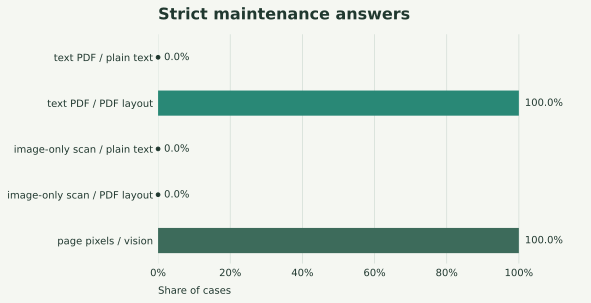

Extraction scorecard and timing: {'mode': 'full', 'development_split_sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'page_families': 12, 'focus_family': 'F250', 'reference': {'format': 'text PDF', 'method': 'PDF layout'}, 'comparisons': [{'format': 'text PDF', 'method': 'plain text', 'pages': 12, 'strict_passes': 0, 'strict_accuracy': 0.0, 'paired_vs_text_pdf_layout': {'delta': -1.0, 'low': -1.0, 'high': -1.0, 'n': 12, 'families': 12}, 'paired_wins': 0, 'paired_losses': 12, 'exact_cells': 12, 'possible_cells': 108, 'exact_numbers': 0, 'possible_numbers': 36, 'cell_fidelity': 0.1111111111111111, 'numeric_exactness': 0.0, 'reading_order_pair_errors': 24, 'missing_headings': 0, 'inverted_heading_pairs': 24, 'pages_with_extra_labels': 12, 'pages_with_duplicate_labels': 0, 'invalid_vision_schema': 0, 'vision_cap_hits': 0, 'median_latency_ms': 5.043172499995308, 'max_latency_ms': 21.06897900000604, 'peak_allocated_bytes': None}, {'format': 'text PDF', 'method': 

PosixPath('evidence/records.json')

In [12]:
groups = defaultdict(list)
for row in records:
    groups[row["format"], row["method"]].append(row)

comparisons = []
by_slice = []
if groups:
    assert len(groups) == 5
    reference_rows = groups[REFERENCE]
    reference_families = [row["family"] for row in reference_rows]
    assert reference_families == [row["family"] for row in fixtures]
    incumbent = [row["strict_correct"] for row in reference_rows]
    for (page_format, method), group in groups.items():
        assert [row["family"] for row in group] == reference_families
        candidate = [row["strict_correct"] for row in group]
        times = [row["elapsed_ms"] for row in group]
        comparisons.append({
            "format": page_format, "method": method, "pages": len(group),
            "strict_passes": sum(candidate),
            "strict_accuracy": sum(candidate) / len(candidate),
            "paired_vs_text_pdf_layout": paired_interval(group, candidate, incumbent),
            "paired_wins": sum(a > b for a, b in zip(candidate, incumbent)),
            "paired_losses": sum(a < b for a, b in zip(candidate, incumbent)),
            "exact_cells": sum(row["exact_cells"] for row in group),
            "possible_cells": sum(row["possible_cells"] for row in group),
            "exact_numbers": sum(row["exact_numbers"] for row in group),
            "possible_numbers": sum(row["possible_numbers"] for row in group),
            "cell_fidelity": sum(row["exact_cells"] for row in group) / sum(row["possible_cells"] for row in group),
            "numeric_exactness": sum(row["exact_numbers"] for row in group) / sum(row["possible_numbers"] for row in group),
            "reading_order_pair_errors": sum(row["reading_order_pair_errors"] for row in group),
            "missing_headings": sum(row["missing_headings"] for row in group),
            "inverted_heading_pairs": sum(row["inverted_heading_pairs"] for row in group),
            "pages_with_extra_labels": sum(bool(row["extra_fault_labels"]) for row in group),
            "pages_with_duplicate_labels": sum(bool(row["duplicate_fault_labels"]) for row in group),
            "invalid_vision_schema": sum(row["extracted"].get("valid_schema") is False for row in group),
            "vision_cap_hits": sum(row["extracted"].get("hit_token_cap") is True for row in group),
            "median_latency_ms": median(times),
            "max_latency_ms": max(times),
            "peak_allocated_bytes": max((row["peak_allocated_bytes"] for row in group
                                         if "peak_allocated_bytes" in row), default=None),
        })
        for category in SLICES:
            cohort = [row for row in group if row["slice"] == category]
            by_slice.append({
                "format": page_format, "method": method, "slice": category,
                "n": len(cohort), "strict_passes": sum(row["strict_correct"] for row in cohort),
            })

failures = [row for row in records if not row["strict_correct"]
            or row["exact_cells"] != row["possible_cells"] or row["reading_order_pair_errors"]
            or row["extra_fault_labels"] or row["duplicate_fault_labels"]]
if failures:
    print("Inspect an extraction failure:", failures[0])
if comparisons:
    chart("Strict maintenance answers", [f'{row["format"]} / {row["method"]}' for row in comparisons],
          [row["strict_accuracy"] for row in comparisons], "fraction")

summary = {
    "mode": "smoke" if COURSE_SMOKE else "full",
    "development_split_sha256": SPLIT_MANIFEST["dev"]["sha256"],
    "page_families": len(fixtures), "focus_family": FOCUS_FAMILY,
    "reference": {"format": REFERENCE[0], "method": REFERENCE[1]},
    "comparisons": comparisons, "by_slice": by_slice,
    "preparation": preparation,
    "artifacts": artifact_paths,
    "vision": {
        "model_id": MODEL_IDS["vision"][0], "revision": MODEL_IDS["vision"][1],
        "load_ms": vision_load_ms, "warmup_ms": vision_warmup_ms,
        "max_new_tokens": VISION_MAX_TOKENS,
    },
    "packages": {name: importlib.metadata.version(name) for name in ("pypdf", "pymupdf", "reportlab")
                 if not COURSE_SMOKE},
    "elapsed_after_bootstrap_seconds": perf_counter() - lab_started,
}
print("Extraction scorecard and timing:", summary)
save("manifest", manifest)
save("failure-gallery", failures)
save("summary", summary)
save("records", records)

## Read the result

Check F-250 in the manifest and compare its recorded rows before using the
scorecard to choose an ingestion path. The scan is clean and has the same
layout as the text PDF. It does not test faded print, phone photographs,
handwriting or unfamiliar tables.

[Return to the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/2-build-the-evidence-layer/04-ingest-documents-with-layout)

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [docling-project/docling](https://github.com/docling-project/docling)
- [Visual Instruction Tuning (LLaVA)](https://arxiv.org/abs/2304.08425)